In [9]:
from pynwb import NWBHDF5IO
import pandas as pd
import numpy as np

FILES = {
    "688277": "../../data/raw/688277-20230921-v001.nwb",
    "692644": "../../data/raw/692644-20230907-v001.nwb",
}
PROBES = ["probeB", "probeD", "probeF"]

# Open one file (this doesn't load the big data yet)
io = NWBHDF5IO(FILES["688277"], "r")
nwbfile = io.read()

# What recordings are in this file? (checking for EEG)
print("Acquisition contents:", list(nwbfile.acquisition.keys()))

# Probe B's LFP and its "seating chart"
lfp = nwbfile.acquisition["LFP"]["ElectricalSeriesprobeB"]
elec = lfp.electrodes.to_dataframe()   # one row per LFP channel, in data order

print("Number of channels:", len(elec))
print("Columns:", elec.columns.tolist())
print("Data shape / type / rate:", lfp.data.shape, lfp.data.dtype, lfp.rate)
elec.head()

Acquisition contents: ['ElectricalSeriesEEG', 'LFP', 'isoflurane_level']
Number of channels: 384
Columns: ['location', 'group', 'is_data_valid', 'probe_vertical_position', 'probe_horizontal_position', 'group_name', 'x', 'y', 'z', 'reference']
Data shape / type / rate: (11534078, 384) int16 None


,location,group,is_data_valid,probe_vertical_position,probe_horizontal_position,group_name,x,y,z,reference
id,,,,,,,,,,
30,VAL,probeB pynwb.ecephys.ElectrodeGroup at 0x46748...,True,20,43,probeB,242.0,175.0,183.0,"stainless steel skull screw, left CB"
31,VAL,probeB pynwb.ecephys.ElectrodeGroup at 0x46748...,True,20,11,probeB,242.0,174.0,183.0,"stainless steel skull screw, left CB"
32,VAL,probeB pynwb.ecephys.ElectrodeGroup at 0x46748...,True,40,59,probeB,242.0,174.0,183.0,"stainless steel skull screw, left CB"
33,AV,probeB pynwb.ecephys.ElectrodeGroup at 0x46748...,True,40,27,probeB,243.0,174.0,183.0,"stainless steel skull screw, left CB"
34,AV,probeB pynwb.ecephys.ElectrodeGroup at 0x46748...,True,60,43,probeB,243.0,174.0,183.0,"stainless steel skull screw, left CB"


In [2]:
# 1. Sampling rate, from the timestamps
ts = lfp.timestamps
print("First timestamps:", ts[:3])
print("Last timestamp (s):", ts[-1], "→ minutes:", ts[-1] / 60)
print("Estimated rate (Hz):", 1 / (ts[1] - ts[0]))

# 2. Conversion factor from int16 to volts
print("Conversion factor:", lfp.conversion)

# 3. How many channels are flagged invalid?
print(elec["is_data_valid"].value_counts())

# 4. Which regions does probe B pass through, and how many channels each?
print(elec["location"].value_counts())

First timestamps: [18.66490541 18.6653054  18.6657054 ]
Last timestamp (s): 4632.285202127705 → minutes: 77.20475336879508
Estimated rate (Hz): 2500.0045749324204
Conversion factor: 1.9499999999999999e-07
is_data_valid
True     370
False     14
Name: count, dtype: int64
location
AV           85
CA3          54
LD           34
fi           32
SSp-tr6a     26
RSPagl2/3    26
SSp-tr5      25
SSp-ll6a     14
CA2          13
null         13
ccb          11
RSPagl5      11
RSPagl1      11
alv          10
cing         10
VAL           3
root          3
SSp-ll6b      2
CA1           1
Name: count, dtype: int64


In [3]:
def region_ranges(elec_df):
    """Group consecutive channels with the same region label into ranges."""
    locs = elec_df["location"].astype(str).to_numpy()
    valid = elec_df["is_data_valid"].astype(bool).to_numpy()
    rows = []
    start = 0
    for ch in range(1, len(locs) + 1):
        # A range ends when the label changes (or we reach the last channel)
        if ch == len(locs) or locs[ch] != locs[start]:
            rows.append({
                "region": locs[start],
                "ch_start": start,
                "ch_end": ch - 1,
                "n_channels": ch - start,
                "n_invalid": int((~valid[start:ch]).sum()),
            })
            start = ch
    return pd.DataFrame(rows)


all_maps = []
for session, path in FILES.items():
    with NWBHDF5IO(path, "r") as io_s:
        nwb_s = io_s.read()
        for probe in PROBES:
            e = nwb_s.acquisition["LFP"][f"ElectricalSeries{probe}"].electrodes.to_dataframe()
            m = region_ranges(e)
            m.insert(0, "probe", probe)
            m.insert(0, "session", session)
            all_maps.append(m)

region_map = pd.concat(all_maps, ignore_index=True)

# Show probe B of the isoflurane file first
region_map[(region_map["session"] == "688277") & (region_map["probe"] == "probeB")]

,session,probe,region,ch_start,ch_end,n_channels,n_invalid
0,688277,probeB,VAL,0,2,3,0
1,688277,probeB,AV,3,87,85,0
2,688277,probeB,LD,88,121,34,0
3,688277,probeB,root,122,124,3,0
4,688277,probeB,fi,125,156,32,0
5,688277,probeB,alv,157,161,5,0
6,688277,probeB,CA3,162,215,54,1
7,688277,probeB,CA2,216,228,13,0
8,688277,probeB,CA1,229,229,1,0
9,688277,probeB,alv,230,234,5,0


In [4]:
for (session, probe), m in region_map.groupby(["session", "probe"]):
    print(f"\n=== {session} {probe} ===")
    print(m[["region", "ch_start", "ch_end", "n_channels", "n_invalid"]].to_string(index=False))


=== 688277 probeB ===
   region  ch_start  ch_end  n_channels  n_invalid
      VAL         0       2           3          0
       AV         3      87          85          0
       LD        88     121          34          0
     root       122     124           3          0
       fi       125     156          32          0
      alv       157     161           5          0
      CA3       162     215          54          1
      CA2       216     228          13          0
      CA1       229     229           1          0
      alv       230     234           5          0
      ccb       235     245          11          0
     cing       246     255          10          0
 SSp-ll6b       256     257           2          0
 SSp-ll6a       258     271          14          0
 SSp-tr6a       272     297          26          0
  SSp-tr5       298     322          25          0
  RSPagl5       323     333          11          0
RSPagl2/3       334     359          26          0
  RSPagl

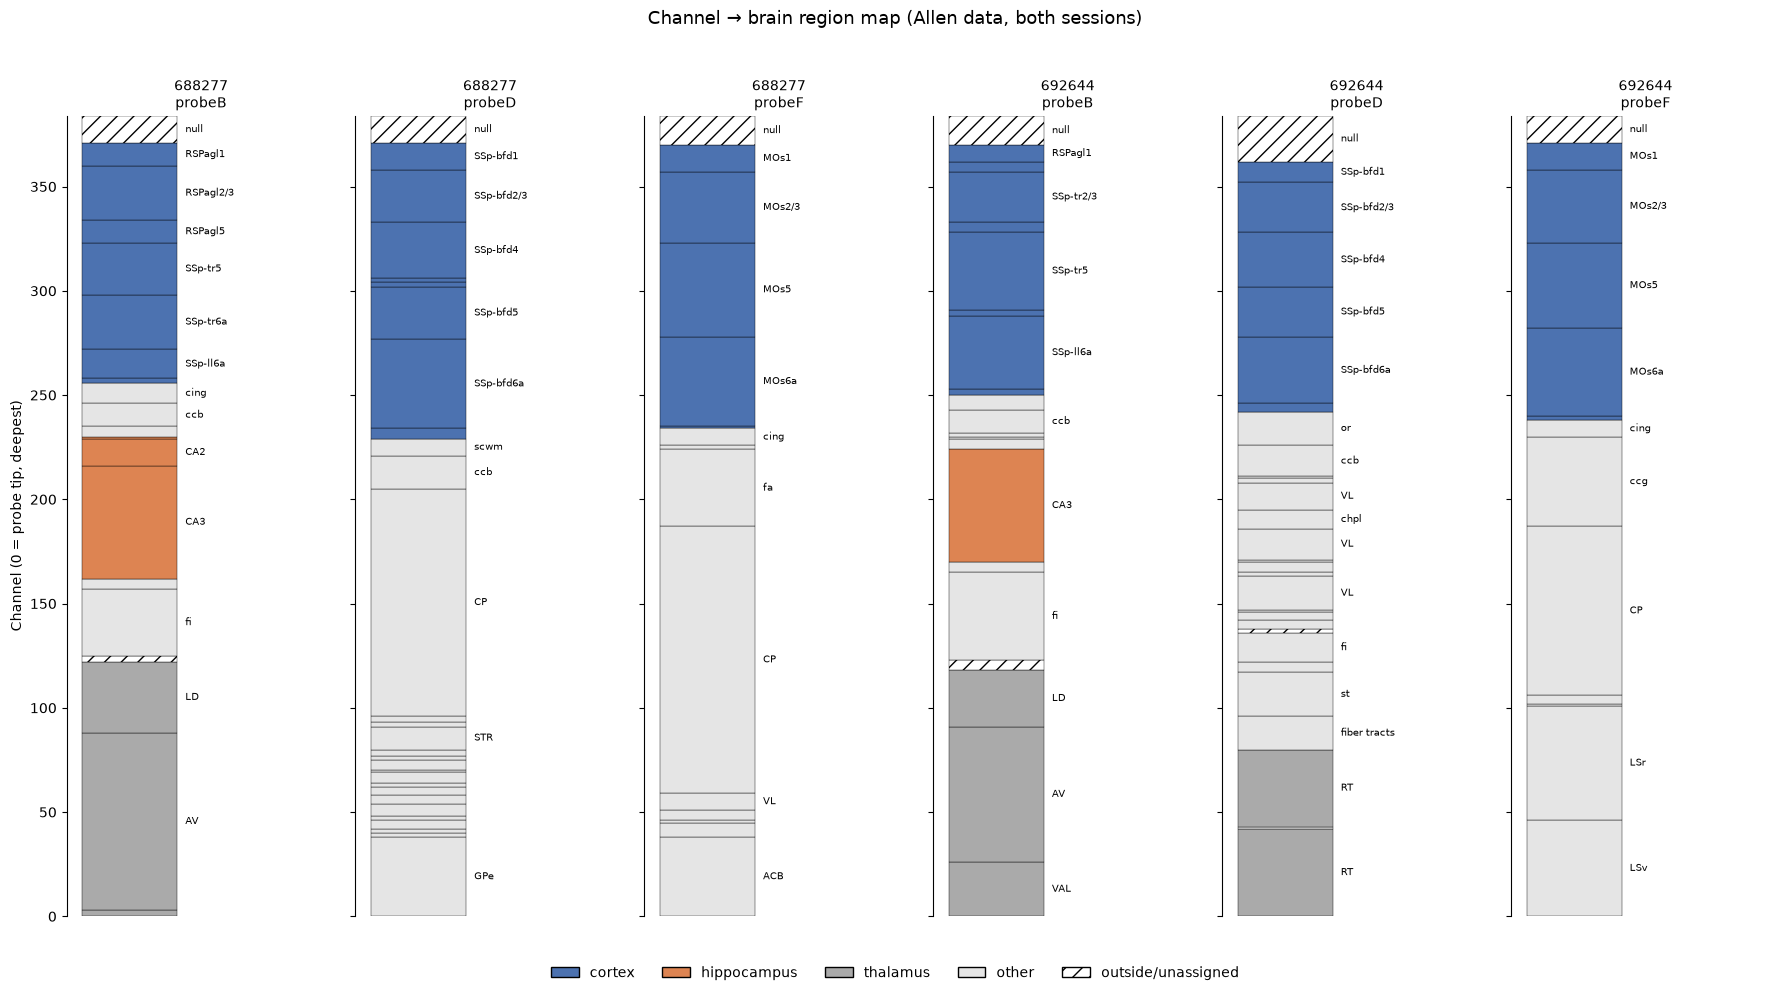

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def region_category(label):
    """Sort Allen region labels into the groups we care about."""
    if label.startswith(("SSp", "MOs", "RSP")):
        return "cortex"
    if label in ("CA1", "CA2", "CA3", "DG"):
        return "hippocampus"
    if label in ("VAL", "AV", "LD", "RT"):
        return "thalamus"
    if label in ("null", "root"):
        return "outside/unassigned"
    return "other"   # striatum, septum, ventricle, fiber tracts, etc.

region_map["category"] = region_map["region"].apply(region_category)

CATEGORY_COLORS = {
    "cortex": "#4C72B0",              # blue
    "hippocampus": "#DD8452",         # orange
    "thalamus": "#AAAAAA",            # dark gray
    "other": "#E5E5E5",               # light gray
    "outside/unassigned": "white",    # hatched
}

groups = list(region_map.groupby(["session", "probe"]))
fig, axes = plt.subplots(1, len(groups), figsize=(18, 10), sharey=True)

for ax, ((session, probe), m) in zip(axes, groups):
    for _, row in m.iterrows():
        # One colored block per region range
        ax.bar(0, row["n_channels"], bottom=row["ch_start"], width=0.6,
               color=CATEGORY_COLORS[row["category"]],
               edgecolor="black", linewidth=0.3,
               hatch="//" if row["category"] == "outside/unassigned" else None)
        # Write the region name next to blocks big enough to read
        if row["n_channels"] >= 8:
            ax.text(0.35, row["ch_start"] + row["n_channels"] / 2, row["region"],
                    va="center", fontsize=7)
    ax.set_title(f"{session}\n{probe}", fontsize=10)
    ax.set_xlim(-0.4, 1.3)
    ax.set_xticks([])
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylim(0, 384)
axes[0].set_ylabel("Channel (0 = probe tip, deepest)")

legend_items = [Patch(facecolor=c, edgecolor="black",
                      hatch="//" if k == "outside/unassigned" else None, label=k)
                for k, c in CATEGORY_COLORS.items()]
fig.legend(handles=legend_items, loc="lower center", ncol=5, frameon=False)
fig.suptitle("Channel → brain region map (Allen data, both sessions)", fontsize=13)
plt.tight_layout(rect=[0, 0.05, 1, 0.96])
    
plt.show()

In [7]:

def load_lfp(nwb, probe, t_start, t_stop, channels):
    """Load a time window of LFP (in µV) for selected channels only."""
    es = nwb.acquisition['LFP'][f'ElectricalSeries{probe}']
    ts = es.timestamps[:]
    i0, i1 = np.searchsorted(ts, [t_start, t_stop])
    channels = np.sort(np.asarray(channels))          # file reads need increasing order
    data = es.data[i0:i1, channels] * es.conversion * 1e6
    fs = 1 / np.mean(np.diff(ts[:1000]))
    return ts[i0:i1], data, fs

In [10]:
def channels_for(nwb, probe, category):
    """Return valid channel numbers on a probe that belong to a region category."""
    e = nwb.acquisition["LFP"][f"ElectricalSeries{probe}"].electrodes.to_dataframe()
    cats = e["location"].astype(str).apply(region_category).to_numpy()
    valid = e["is_data_valid"].astype(bool).to_numpy()
    return np.where((cats == category) & valid)[0]

# Quick check on the isoflurane file
for probe in PROBES:
    ctx = channels_for(nwbfile, probe, "cortex")
    hip = channels_for(nwbfile, probe, "hippocampus")
    print(f"{probe}: cortex {len(ctx)} ch ({ctx.min()}–{ctx.max()}), "
          f"hippocampus {len(hip)} ch" + (f" ({hip.min()}–{hip.max()})" if len(hip) else ""))

probeB: cortex 115 ch (256–370), hippocampus 67 ch (162–229)
probeD: cortex 142 ch (229–370), hippocampus 0 ch
probeF: cortex 136 ch (234–369), hippocampus 0 ch


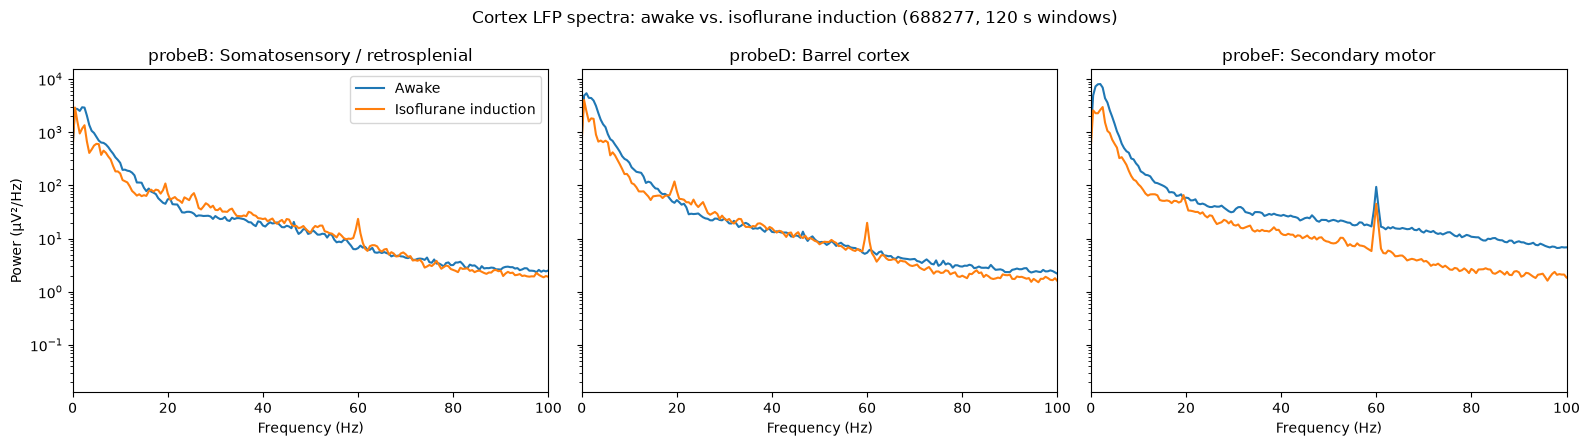

In [14]:
from scipy import signal

def compute_psd(data, fs):
    """PLACEHOLDER spectrum (TASKS.md settings). Swap in Justin's function later."""
    f, psd = signal.welch(data, fs=fs, nperseg=int(fs * 2), axis=0)
    return f, psd          # psd: one column per channel

WIN_LEN = 120   # 2-minute windows, per the POC
WINDOWS_ISO = {
    "Awake": 600,
    "Isoflurane induction": 2281,   # last 2 min of the 5% period (2129–2401 s)
}
AREA = {
    "probeB": "Somatosensory / retrosplenial",
    "probeD": "Barrel cortex",
    "probeF": "Secondary motor",
}

def region_psd(nwb, probe, category, t_start, win_len=WIN_LEN):
    """Average spectrum across all valid channels of one region on one probe."""
    chans = channels_for(nwb, probe, category)
    _, data, fs = load_lfp(nwb, probe, t_start, t_start + win_len, chans)
    f, psd = compute_psd(data, fs)
    return f, psd.mean(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, probe in zip(axes, PROBES):
    for label, t0 in WINDOWS_ISO.items():
        f, p = region_psd(nwbfile, probe, "cortex", t0)
        ax.semilogy(f, p, label=label)
    ax.set_xlim(0, 100)
    ax.set_title(f"{probe}: {AREA[probe]}")
    ax.set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Power (µV²/Hz)")
axes[0].legend()
fig.suptitle("Cortex LFP spectra: awake vs. isoflurane induction (688277, 120 s windows)")
plt.tight_layout()
plt.show()

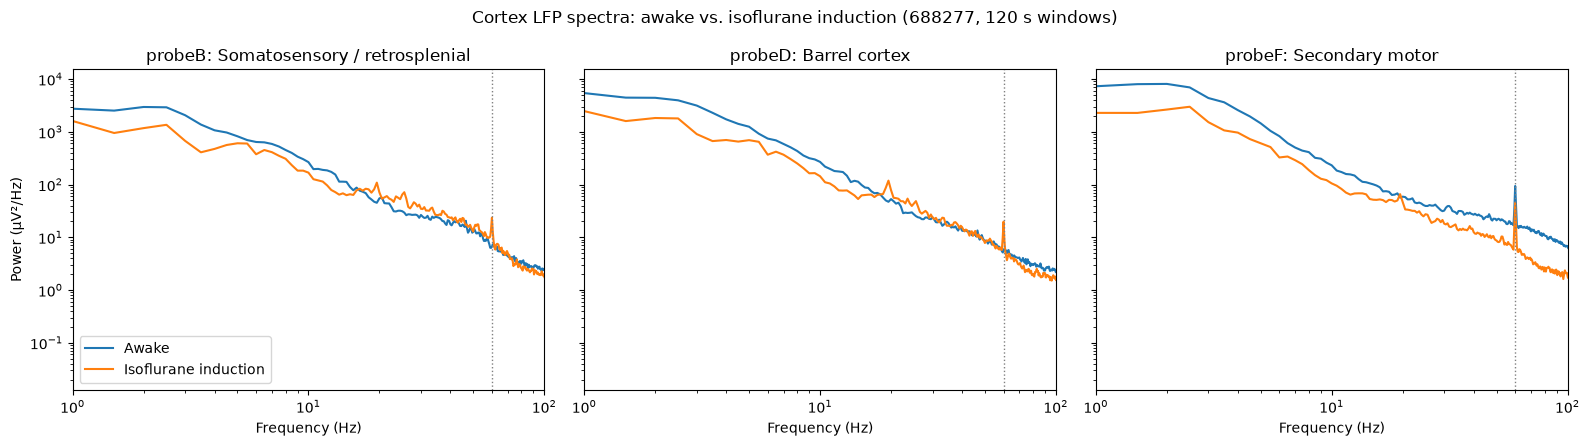

In [15]:
# Compute once and store, so replotting doesn't reload data
iso_spectra = {}   # key: (probe, window label) -> (f, power)
for probe in PROBES:
    for label, t0 in WINDOWS_ISO.items():
        iso_spectra[(probe, label)] = region_psd(nwbfile, probe, "cortex", t0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, probe in zip(axes, PROBES):
    for label in WINDOWS_ISO:
        f, p = iso_spectra[(probe, label)]
        ax.loglog(f[1:], p[1:], label=label)      # f[1:] skips 0 Hz
    ax.axvline(60, color="gray", ls=":", lw=1)     # mark line noise
    ax.set_xlim(1, 100)
    ax.set_title(f"{probe}: {AREA[probe]}")
    ax.set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Power (µV²/Hz)")
axes[0].legend()
fig.suptitle("Cortex LFP spectra: awake vs. isoflurane induction (688277, 120 s windows)")
plt.tight_layout()
plt.show()

In all three cortical areas, low-frequency (1–10 Hz) power was lower during the last 2 minutes of 5% isoflurane induction than during awake baseline

Highest isoflurane value: 5.001242315085089
Peak-dose period: 2129 s to 2401 s (35.5 to 40.0 min)


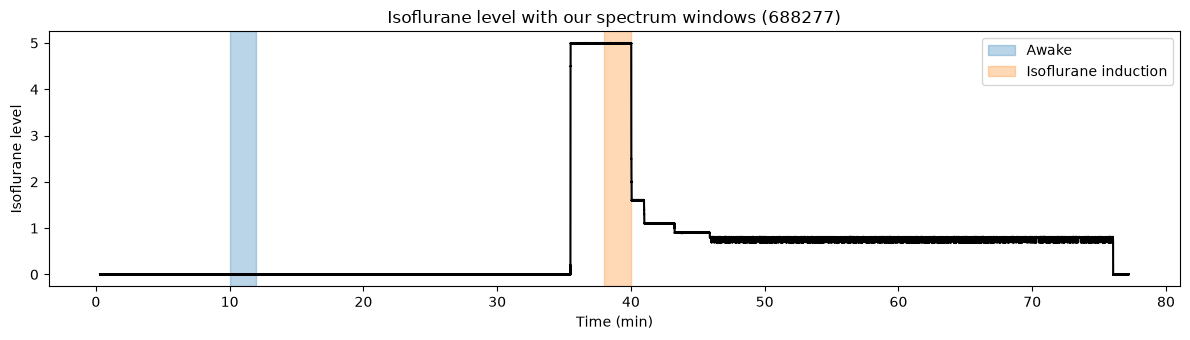

In [16]:
# Isoflurane level over the session
iso = nwbfile.acquisition["isoflurane_level"]
iso_vals = iso.data[:]
if iso.timestamps is not None:
    iso_t = iso.timestamps[:]
else:
    iso_t = iso.starting_time + np.arange(len(iso_vals)) / iso.rate

# When was the dose at its peak (the 5% induction)?
print("Highest isoflurane value:", iso_vals.max())
high = iso_t[iso_vals >= 0.9 * iso_vals.max()]
print(f"Peak-dose period: {high.min():.0f} s to {high.max():.0f} s "
      f"({high.min()/60:.1f} to {high.max()/60:.1f} min)")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(iso_t / 60, iso_vals, color="black")
colors = {"Awake": "tab:blue", "Isoflurane induction": "tab:orange"}
for label, t0 in WINDOWS_ISO.items():
    ax.axvspan(t0 / 60, (t0 + WIN_LEN) / 60, color=colors[label], alpha=0.3, label=label)
ax.set_xlabel("Time (min)")
ax.set_ylabel("Isoflurane level")
ax.set_title("Isoflurane level with our spectrum windows (688277)")
ax.legend()
plt.tight_layout()
plt.show()

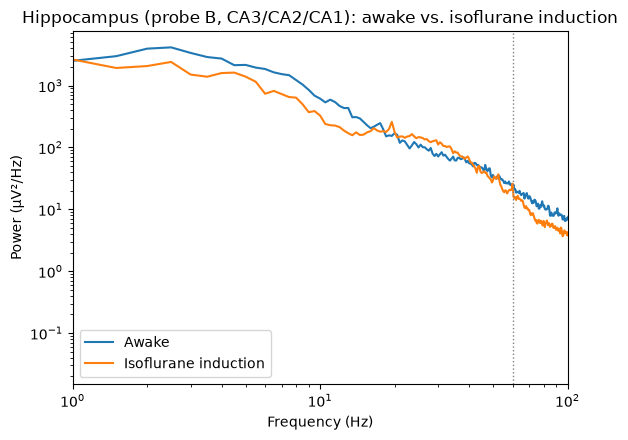

In [17]:
hip_spectra = {}
for label, t0 in WINDOWS_ISO.items():
    hip_spectra[label] = region_psd(nwbfile, "probeB", "hippocampus", t0)

fig, ax = plt.subplots(figsize=(6, 4.5))
for label, (f, p) in hip_spectra.items():
    ax.loglog(f[1:], p[1:], label=label)
ax.axvline(60, color="gray", ls=":", lw=1)   # line noise
ax.set_xlim(1, 100)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power (µV²/Hz)")
ax.set_title("Hippocampus (probe B, CA3/CA2/CA1): awake vs. isoflurane induction")
ax.legend()
plt.tight_layout()
plt.show()

In this mouse (688277), hippocampal LFP during the last 2 minutes of 5% isoflurane induction had about 2× less power at low frequencies (~2–15 Hz) and somewhat less high-gamma power (>60 Hz) than during the awake baseline, matching the low-frequency drop seen in all three cortical areas. The awake spectrum showed no clear theta peak (6–10 Hz), suggesting the mouse was likely at rest during the baseline window; this is a single session and single 2-minute window per condition, so the result is suggestive rather than conclusive.

In [20]:
eeg = nwbfile.acquisition["ElectricalSeriesEEG"]
eeg_elec = eeg.electrodes.to_dataframe()

print("Shape / type:", eeg.data.shape, eeg.data.dtype)
print("Rate:", eeg.rate, "| conversion:", eeg.conversion)
if eeg.timestamps is not None:
    print("First / last time (s):", eeg.timestamps[0], eeg.timestamps[-1])
print("Number of EEG electrodes:", len(eeg_elec))
print("Columns:", eeg_elec.columns.tolist())
eeg_elec.head(5)

Shape / type: (11534080, 30) int16
Rate: None | conversion: 1.949999928474426e-07
First / last time (s): 18.60923773647054 4632.240564105999
Number of EEG electrodes: 30
Columns: ['location', 'group', 'is_data_valid', 'probe_vertical_position', 'probe_horizontal_position', 'group_name', 'x', 'y', 'z', 'reference']


,location,group,is_data_valid,probe_vertical_position,probe_horizontal_position,group_name,x,y,z,reference
id,,,,,,,,,,
0,VISl,EEG array pynwb.ecephys.ElectrodeGroup at 0x51...,True,-1,-1,EEG array,377.0,58.0,82.0,"stainless steel skull screw, mid CB"
1,VISp,EEG array pynwb.ecephys.ElectrodeGroup at 0x51...,True,-1,-1,EEG array,377.0,24.0,141.0,"stainless steel skull screw, mid CB"
2,RSPagl,EEG array pynwb.ecephys.ElectrodeGroup at 0x51...,True,-1,-1,EEG array,377.0,20.0,188.0,"stainless steel skull screw, mid CB"
3,VISal,EEG array pynwb.ecephys.ElectrodeGroup at 0x51...,True,-1,-1,EEG array,333.0,47.0,79.0,"stainless steel skull screw, mid CB"
4,VISp,EEG array pynwb.ecephys.ElectrodeGroup at 0x51...,True,-1,-1,EEG array,333.0,25.0,119.0,"stainless steel skull screw, mid CB"


EEG unit: volts | data shape: (11534080, 30)
EEG sampling rate (Hz): 2500.0


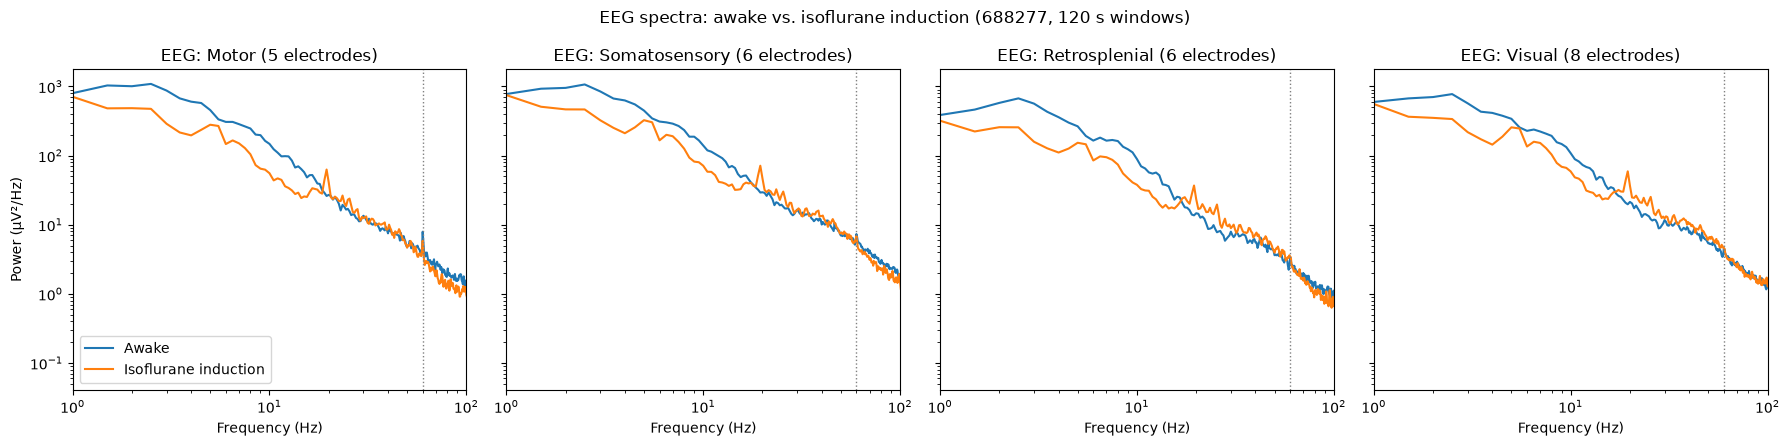

In [24]:
eeg = nwbfile.acquisition["ElectricalSeriesEEG"]
print("EEG unit:", eeg.unit, "| data shape:", eeg.data.shape)

def eeg_area(label):
    """Group EEG electrode labels into broad cortical areas."""
    if label.startswith("MO"):  return "Motor"
    if label.startswith("SSp"): return "Somatosensory"
    if label.startswith("RSP"): return "Retrosplenial"
    if label.startswith("VIS"): return "Visual"
    return "Other"

eeg_elec["area"] = eeg_elec["location"].astype(str).apply(eeg_area)
eeg_valid = eeg_elec["is_data_valid"].astype(bool).to_numpy().copy()
EEG_EXCLUDE = [26, 29]   # visual electrodes with broadband noise + 60 Hz during induction (see per-electrode plot)
eeg_valid[EEG_EXCLUDE] = False

def load_eeg(nwb, t_start, t_stop, channels):
    """Load a time window of EEG (in µV) for selected electrodes."""
    es = nwb.acquisition["ElectricalSeriesEEG"]
    if es.timestamps is not None:
        ts = es.timestamps[:]
    else:
        ts = es.starting_time + np.arange(es.data.shape[0]) / es.rate
    i0, i1 = np.searchsorted(ts, [t_start, t_stop])
    channels = np.sort(np.asarray(channels))
    data = es.data[i0:i1, channels] * es.conversion * 1e6
    fs = 1 / np.mean(np.diff(ts[:1000]))
    return ts[i0:i1], data, fs

EEG_AREAS = ["Motor", "Somatosensory", "Retrosplenial", "Visual"]
eeg_spectra = {}
for area in EEG_AREAS:
    chans = np.where((eeg_elec["area"].to_numpy() == area) & eeg_valid)[0]
    for label, t0 in WINDOWS_ISO.items():
        _, data, fs = load_eeg(nwbfile, t0, t0 + WIN_LEN, chans)
        f, psd = compute_psd(data, fs)
        eeg_spectra[(area, label)] = (f, psd.mean(axis=1), len(chans))
print("EEG sampling rate (Hz):", round(fs, 1))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, area in zip(axes, EEG_AREAS):
    for label in WINDOWS_ISO:
        f, p, n = eeg_spectra[(area, label)]
        ax.loglog(f[1:], p[1:], label=label)
    ax.axvline(60, color="gray", ls=":", lw=1)
    ax.set_xlim(1, 100)
    ax.set_title(f"EEG: {area} ({n} electrodes)")
    ax.set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Power (µV²/Hz)")
axes[0].legend()
fig.suptitle("EEG spectra: awake vs. isoflurane induction (688277, 120 s windows)")
plt.tight_layout()
plt.show()

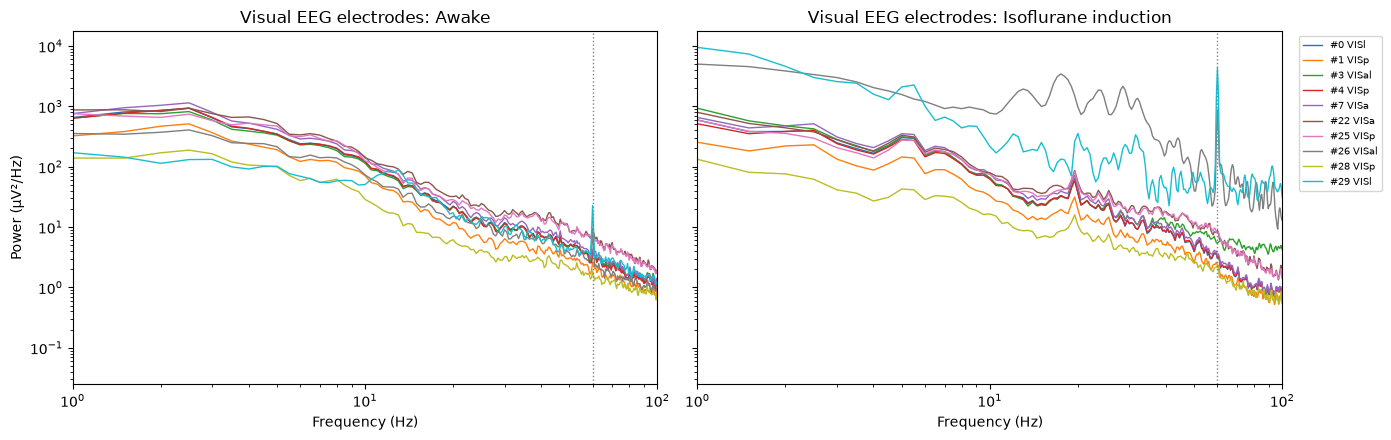

In [25]:
eeg_elec["area"] = eeg_elec["location"].astype(str).apply(eeg_area)
vis = np.where((eeg_elec["area"].to_numpy() == "Visual") & eeg_elec["is_data_valid"].astype(bool).to_numpy())[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (label, t0) in zip(axes, WINDOWS_ISO.items()):
    _, data, fs = load_eeg(nwbfile, t0, t0 + WIN_LEN, vis)
    f, psd = compute_psd(data, fs)
    for i, ch in enumerate(vis):
        ax.loglog(f[1:], psd[1:, i], lw=1,
                  label=f"#{ch} {eeg_elec['location'].iloc[ch]}")
    ax.axvline(60, color="gray", ls=":", lw=1)
    ax.set_xlim(1, 100)
    ax.set_title(f"Visual EEG electrodes: {label}")
    ax.set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Power (µV²/Hz)")
axes[1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

EEG over all four cortical areas (motor, somatosensory, retrosplenial, visual) showed the same pattern as the LFP: about 2× less power at ~1–15 Hz during the last 2 minutes of 5% isoflurane than during awake baseline, with similar power above ~20 Hz. Two visual electrodes (#26 VISal, #29 VISl) were excluded because they showed broadband noise and strong 60 Hz line noise only during induction (see per-electrode plot); a sharp ~20 Hz peak present in all channels during induction is likely equipment noise rather than brain activity.